In [1]:
import numpy as np
import torch
torch.manual_seed(42)
# embdata=np.load('embdata.npy')
# ydata_norm=np.load('ydata_norm.npy')
np.random.seed(42)
ydata=np.load('ydata.npy')
sampled_point=np.load('sp.npy')
sp5index=np.array([1,3,5,7,9])-1
sp3index=np.array([1,5,9])-1
sp5=sampled_point[:,sp5index]
sp3=sampled_point[:,sp3index]

def normalize(x,x_max,x_min):
    # if x_max==x_min:
    #     return np.zeros_like(x)
    return (x-x_min)/(x_max-x_min)*2-1

def denormalize(x,x_max,x_min):
    drange=x_max-x_min
    return (x+1)/2*drange+x_min

sp5max=np.max(sp5,axis=1)
sp5min=np.min(sp5,axis=1)

sp5max_max=sp5max.max()
sp5max_min=sp5max.min()
sp5min_max=sp5min.max()
sp5min_min=sp5min.min()

sp5max_n=normalize(sp5max,sp5max_max,sp5max_min)
sp5min_n=normalize(sp5min,sp5min_max,sp5min_min)

sp5n=normalize(sp5,sp5max.reshape(-1,1),sp5min.reshape(-1,1))

embdata=np.concatenate((sp5n,sp5max_n.reshape(-1,1),sp5min_n.reshape(-1,1)),axis=1)
ydata_norm=normalize(ydata,sp5max.reshape(-1,1,1),sp5min.reshape(-1,1,1))

array=np.arange(0,ydata_norm.shape[0])
index=np.random.choice(array,10000,replace=False)

v_ydata=ydata_norm[index]
v_emb=embdata[index]
t_ydata=np.delete(ydata_norm,index,0)
t_emb=np.delete(embdata,index,0)

from torch.utils.data import Dataset,DataLoader
class MyDataset(Dataset):
    def __init__(self,embdata,ydata):
        self.embdata=embdata
        self.ydata=ydata
    def __len__(self):
        return len(self.embdata)
    def __getitem__(self,idx):
        return self.embdata[idx],self.ydata[idx]

train_dataset=MyDataset(t_emb,t_ydata)
val_dataset=MyDataset(v_emb,v_ydata)
train_loader=DataLoader(train_dataset,batch_size=32)
val_loader=DataLoader(val_dataset,batch_size=50)

In [2]:
import torch
import torch.nn as nn
from tqdm import tqdm
from diffusion_model import DiffusionModel
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device="cuda:1"

diffusion=DiffusionModel(
    image_size=(40,240),
    channels=1,
    cond_dim=7,
    timesteps=1000,
    device=device
)

diffusion.load('final_model_sp5_0319.pt')

diffusion.model.eval()
y_true=np.empty((0,40,240))
y_pred=np.empty((0,40,240))
x_in=np.empty((0,7))
for veb,vyb in tqdm(val_loader):
    x_in=np.concatenate((x_in,veb.numpy()),axis=0)
    y_true=np.concatenate((y_true,vyb.numpy()),axis=0)
    veb=veb.to(device)
    # vyb=vyb.unsqueeze(1).to(device)
    sample=diffusion.generate(veb, num_samples=vyb.size(0))
    y_pred=np.concatenate((y_pred,sample[:,0,:,:]),axis=0)
    # break

Model loaded from final_model_sp5_0319.pt


100%|██████████| 200/200 [15:45:00<00:00, 283.50s/it]  


In [3]:
i=10
print(y_pred[i])
print(y_true[i])

x_in.shape, y_true.shape, y_pred.shape

[[-0.99880797 -1.00346804 -1.00314701 ...  0.40646657  0.41421843
   0.43794787]
 [-0.95592248 -0.95459956 -0.95309514 ...  0.43542528  0.44742239
   0.45909682]
 [-0.90738255 -0.90815139 -0.90788537 ...  0.46374139  0.47516981
   0.48626986]
 ...
 [-0.04639928 -0.04719593 -0.04901193 ...  0.97749889  0.98783541
   0.99562246]
 [-0.0441781  -0.04485858 -0.04383725 ...  0.98034257  0.98690432
   0.99587637]
 [-0.04551399 -0.04029002 -0.04336304 ...  0.9841634   0.98917073
   0.99868345]]
[[-1.         -1.         -1.         ...  0.40437675  0.41769743
   0.42911518]
 [-0.95432919 -0.95432919 -0.95432919 ...  0.43482399  0.44624162
   0.45765936]
 [-0.90865844 -0.90865844 -0.90675545 ...  0.46146524  0.47288299
   0.48620367]
 ...
 [-0.05042815 -0.05042815 -0.05042815 ...  0.97906756  0.98667932
   0.99619412]
 [-0.04852521 -0.04852521 -0.04662228 ...  0.9809705   0.99048531
   0.99809706]
 [-0.04662228 -0.04662228 -0.04662228 ...  0.98287344  0.99238825
   1.        ]]


((10000, 7), (10000, 40, 240), (10000, 40, 240))

In [4]:
spmax_vector=denormalize(x_in[:,5],sp5max_max,sp5max_min).reshape(-1,1,1)
spmin_vector=denormalize(x_in[:,6],sp5min_max,sp5min_min).reshape(-1,1,1)

true=denormalize(y_true,spmax_vector,spmin_vector)
pred=denormalize(y_pred,spmax_vector,spmin_vector)
spmax_vector.shape,spmin_vector.shape,true.shape, pred.shape

((10000, 1, 1), (10000, 1, 1), (10000, 40, 240), (10000, 40, 240))

In [5]:
def calculate_rmse(matrix1, matrix2):
    error = matrix1 - matrix2    
    # 计算均方误差 (MSE)
    mse = np.mean(error ** 2)    
    # 计算均方根误差 (RMSE)
    rmse = np.sqrt(mse)    
    return rmse
sp5_rmse=[]
for i in range(true.shape[0]):
    rmse=calculate_rmse(true[i],pred[i])
    sp5_rmse.append(rmse)

np.save('sp5_rmse.npy', np.array(sp5_rmse))
np.array(sp5_rmse).shape

(10000,)

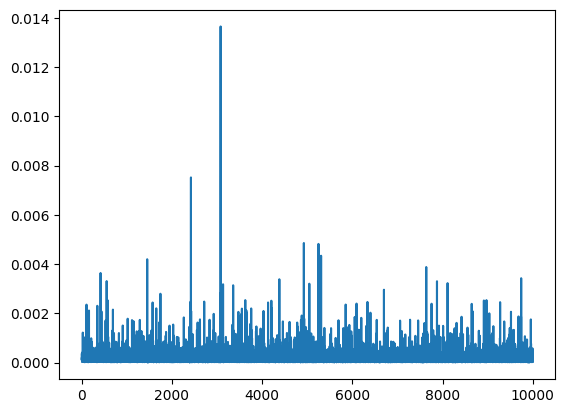

In [6]:
import matplotlib.pyplot as plt
plt.plot(sp5_rmse)

In [7]:
np.mean(sp5_rmse)

np.float64(0.0002161245333776245)

In [8]:
# np.mean(np.load('sp9_rmse.npy'))

In [9]:
pred.dtype

dtype('float64')

In [10]:
pred[10]

array([[288.77363978, 288.77356505, 288.7735702 , ..., 288.79617615,
        288.79630046, 288.79668101],
       [288.77432754, 288.77434875, 288.77437288, ..., 288.79664056,
        288.79683296, 288.79702018],
       [288.77510597, 288.77509364, 288.77509791, ..., 288.79709466,
        288.79727794, 288.79745595],
       ...,
       [288.78891355, 288.78890077, 288.78887165, ..., 288.80533378,
        288.80549955, 288.80562443],
       [288.78894917, 288.78893825, 288.78895463, ..., 288.80537939,
        288.80548462, 288.8056285 ],
       [288.78892774, 288.78901152, 288.78896224, ..., 288.80544066,
        288.80552097, 288.80567352]], shape=(40, 240))

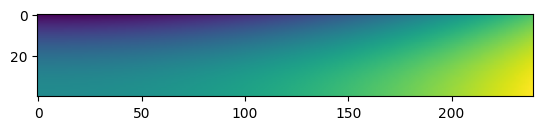

In [11]:
import matplotlib.pyplot as plt
plt.imshow(pred[10], cmap='viridis')